<a href="https://colab.research.google.com/github/davijsf/inteligencia-artificial/blob/main/rede_mlp_ia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np, torch, torch.nn as nn
from sklearn.datasets import load_iris
SEED = 42
torch.manual_seed(SEED)
iris = load_iris()
X = torch.tensor(iris.data, dtype=torch.float32) # (150, 4)
y = torch.tensor(iris.target, dtype=torch.long) # (150,) 3 classes
# divisão treino/teste (80/20) reprodutível
perm = torch.randperm(len(X),
generator=torch.Generator().manual_seed(SEED))
n_tr = int(0.8 * len(X))
Xtr, ytr = X[perm[:n_tr]], y[perm[:n_tr]]
Xte, yte = X[perm[n_tr:]], y[perm[n_tr:]]
# padronização com as estatísticas SÓ do treino
mu, sd = Xtr.mean(0), Xtr.std(0)
Xtr, Xte = (Xtr - mu) / sd, (Xte - mu) / sd

print(Xtr.shape, Xte.shape);

torch.Size([120, 4]) torch.Size([30, 4])


In [2]:
# Exercício 1
class MLP(nn.Module):

    def __init__(self):
        super().__init__()
        self.rede = nn.Sequential(
            nn.Linear(4, 16), # entrada -> oculta 1
            nn.ReLU(),
            nn.Linear(16, 16), # oculta 1 -> oculta 2
            nn.ReLU(),
            nn.Linear(16, 3), # oculta 2 -> saída (3 classes)
        )

    def forward(self, x):
        return self.rede(x)

modelo = MLP()
n_params = sum(p.numel() for p in modelo.parameters())
print(n_params) # esperado: 403


403


época   0 | perda = 1.0957
época   1 | perda = 1.0640
época   2 | perda = 1.0346
época   5 | perda = 0.9352
época  10 | perda = 0.7096
época  25 | perda = 0.2821
época  50 | perda = 0.0590
época 100 | perda = 0.0094
época 199 | perda = 0.0003


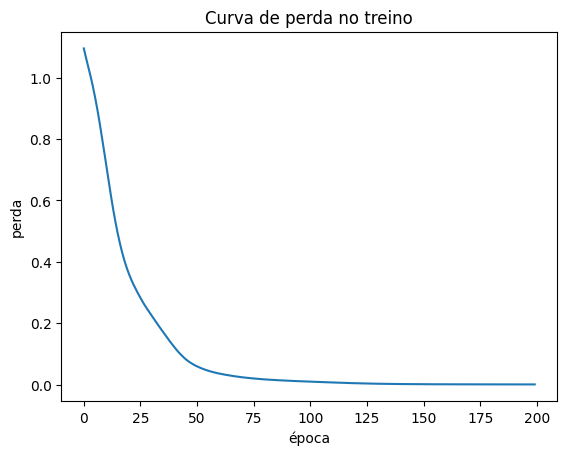

In [3]:
# Exercício 2
import matplotlib.pyplot as plt

criterio = nn.CrossEntropyLoss()
otimizador = torch.optim.Adam(modelo.parameters(), lr=1e-2)

hist = []
for epoca in range(200):
    otimizador.zero_grad()          # 1) zera gradientes acumulados
    saida = modelo(Xtr)             # 2) forward (lote inteiro: 120 amostras)
    perda = criterio(saida, ytr)    # 3) calcula a perda
    perda.backward()                # 4) retropropagação: preenche p.grad
    otimizador.step()               # 5) atualiza os pesos
    hist.append(perda.item())

for e in [0, 1, 2, 5, 10, 25, 50, 100, 199]:
    print(f"época {e:3d} | perda = {hist[e]:.4f}")

plt.plot(hist);
plt.xlabel("época");
plt.ylabel("perda");
plt.title("Curva de perda no treino");
plt.show();

Sem `backward()`, o `p.grad` nunca é preenchido. O `step()` então não tem o que usar e não muda nenhum peso. Com os pesos congelados, a rede calcula a mesma perda em toda iteração. Sem `zero_grad()`, o PyTorch acumula os gradientes de todas as iterações em `p.grad`, então a atualização usa uma direção 'suja' pelas iterações passadas e o treino se degrada.

In [4]:
modelo.eval()           # modo de avaliação
with torch.no_grad():   # não contrói grafo de gradiente
    pred_tr = modelo(Xtr).argmax(dim=1)
    pred_te = modelo(Xte).argmax(dim=1)

acc_tr = (pred_tr == ytr).float().mean().item()
acc_te = (pred_te == yte).float().mean().item()
print(f"acurácia de treino: {acc_tr:.4f} ({int(acc_tr*len(ytr) )} / {len(ytr)})")
print(f"acurácia de teste: {acc_te:.4f} ({int(acc_te*len(yte))}/{len(yte)})")





acurácia de treino: 1.0000 (120 / 120)
acurácia de teste: 0.9000 (26/30)


[[ 6  0  0]
 [ 0  7  3]
 [ 0  0 14]]


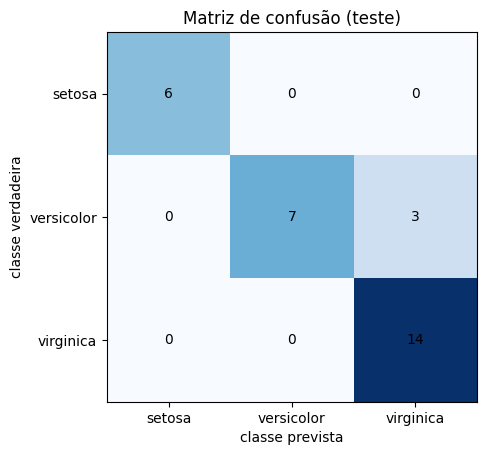

In [7]:
cm = np.zeros((3, 3), dtype=int)
for verdadeira, prevista in zip(yte.tolist(), pred_te.tolist()):
    cm[verdadeira, prevista] += 1   # linha = verdadeira, coluna = prevista

print(cm)

# visualização
fig, ax = plt.subplots()
ax.imshow(cm, cmap="Blues")
nomes = iris.target_names   # setosa, versicolor, virginica
ax.set_xticks(range(3)); ax.set_xticklabels(nomes)
ax.set_yticks(range(3)); ax.set_yticklabels(nomes)
ax.set_xlabel("classe prevista"); ax.set_ylabel("classe verdadeira")
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center")
plt.title("Matriz de confusão (teste)")
plt.show()

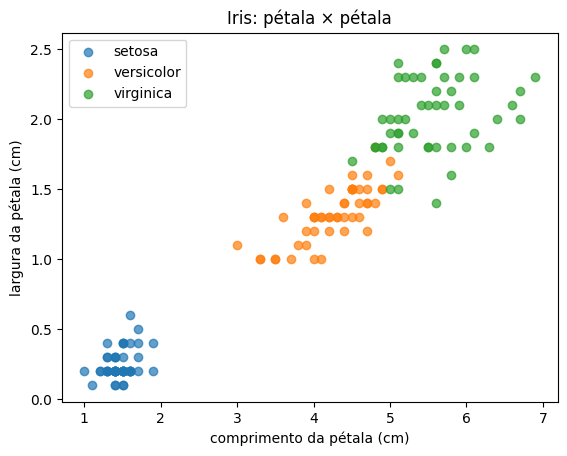

In [10]:
# usa os dados originais (sem padronizar) para ler os valores em cm
cores = ["tab:blue", "tab:orange", "tab:green"]
for k, nome in enumerate(iris.target_names):
    idx = iris.target == k
    plt.scatter(iris.data[idx, 2], iris.data[idx, 3], c=cores[k], label=nome, alpha=0.7)
plt.xlabel("comprimento da pétala (cm)"); plt.ylabel("largura da pétala (cm)")
plt.legend(); plt.title("Iris: pétala × pétala"); plt.show()

A matriz de confusão mostra que a rede acertou todas as setosas `(6/6)` e todas as virginicas `(14/14)`. Os `3` erros estão concentrados em um único sentido: **versicolor** classificada como **virginica**. Isso acontece porque a **setosa** é bem isolada das outras espécies no espaço dos atributos, principalmente nas medidas da pétala, enquanto versicolor e virginica têm características sobrepostas, com pontos de uma classe caindo na região da outra. A rede atingiu `100%` de acurácia no treino, ou seja, ajustou a fronteira entre as duas classes aos exemplos que viu, mas nas amostras novas que caíram na zona de sobreposição ela errou (teste ≈ 90%), um sinal inicial de overfitting. A incerteza nessa região também aparece no softmax: uma das amostras de teste recebeu 81% para virginica e 19% para versicolor, enquanto as demais ficaram acima de 99% de confiança.



In [9]:
with torch.no_grad():
    logits = modelo(Xte[:5])

# (a) cada linha do softmax soma 1?
probs = torch.softmax(logits, dim=1)
print(probs)
print("soma por linha:", probs.sum(dim=1))   # esperado: tensor([1., 1., 1., 1., 1.])

# (b) CrossEntropyLoss == NLLLoss sobre log_softmax?
alvo = yte[:5]
ce  = nn.CrossEntropyLoss()(logits, alvo)
nll = nn.NLLLoss()(torch.log_softmax(logits, dim=1), alvo)
print(ce.item(), nll.item())
print("iguais?", torch.allclose(ce, nll))    # esperado: True

tensor([[1.4585e-06, 1.8893e-01, 8.1106e-01],
        [2.6072e-09, 5.8678e-06, 9.9999e-01],
        [2.5858e-07, 9.4535e-03, 9.9055e-01],
        [3.7826e-06, 9.9999e-01, 3.3689e-06],
        [2.8397e-06, 9.9999e-01, 8.2387e-06]])
soma por linha: tensor([1., 1., 1., 1., 1.])
0.335175096988678 0.335175096988678
iguais? True


In [11]:
def treinar_com(fabrica_otimizador, epocas=200):
    torch.manual_seed(SEED)                 # mesmos pesos iniciais em todos
    m    = MLP()                            # modelo NOVO a cada configuração
    opt  = fabrica_otimizador(m.parameters())
    crit = nn.CrossEntropyLoss()
    for _ in range(epocas):
        opt.zero_grad()
        perda = crit(m(Xtr), ytr)
        perda.backward()
        opt.step()
    m.eval()
    with torch.no_grad():
        perda_final = crit(m(Xtr), ytr).item()
        acc_te = (m(Xte).argmax(dim=1) == yte).float().mean().item()
    return perda_final, acc_te

configs = {
    "SGD  lr=1e-2":            lambda p: torch.optim.SGD(p, lr=1e-2),
    "SGD  lr=0.1, mom=0.9":    lambda p: torch.optim.SGD(p, lr=0.1, momentum=0.9),
    "Adam lr=1e-2":            lambda p: torch.optim.Adam(p, lr=1e-2),
}

print(f"{'otimizador':24s} | perda final | acc teste")
for nome, fab in configs.items():
    perda_f, acc = treinar_com(fab)
    print(f"{nome:24s} | {perda_f:11.6f} | {acc:.4f}")

otimizador               | perda final | acc teste
SGD  lr=1e-2             |    0.807871 | 0.8333
SGD  lr=0.1, mom=0.9     |    0.004498 | 0.9000
Adam lr=1e-2             |    0.000288 | 0.9000
